In [70]:
from google.colab import files
uploaded = files.upload()

Saving online_shoppers_intention.csv to online_shoppers_intention (2).csv


In [71]:
pip install streamlit

In [72]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
import joblib
import scipy.stats as stats
import streamlit as st

In [73]:
df = pd.read_csv('/content/online_shoppers_intention.csv')
print(df)

       Administrative  Administrative_Duration  Informational  \
0                   0                      0.0              0   
1                   0                      0.0              0   
2                   0                      0.0              0   
3                   0                      0.0              0   
4                   0                      0.0              0   
...               ...                      ...            ...   
12325               3                    145.0              0   
12326               0                      0.0              0   
12327               0                      0.0              0   
12328               4                     75.0              0   
12329               0                      0.0              0   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                         0.0               1                 0.000000   
1                         0.0               2                64.000000 

In [34]:
# EDA

In [74]:
print("Shape of dataSet:",df.shape)

Shape of dataSet: (12330, 18)


In [75]:
df.isna().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


This Data has zero missing values


In [76]:
df.duplicated().sum()

np.int64(125)

In [77]:
df = df.drop_duplicates().reset_index(drop=True)

In [78]:
df.shape

(12205, 18)

In [110]:

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Remove Cluster from the prediction dataset
df = df.drop(columns=["Cluster"], errors="ignore").copy()

# 2. Separate features and target
X = df.drop(columns=["Revenue"])
y = df["Revenue"].astype(int)

# 3. Identify categorical and numeric columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

# 4. Build preprocessing steps
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
print("Preprocessor is ready.")


Numeric columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Categorical columns: []
Preprocessor is ready.


In [111]:
print("Data type of each colums")
df.dtypes

Data type of each colums


,0
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


In [112]:
df.dtypes.value_counts()

,count
int64,11
float64,7


In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   BounceRates              12205 non-null  float64
 7   ExitRates                12205 non-null  float64
 8   PageValues               12205 non-null  float64
 9   SpecialDay               12205 non-null  float64
 10  Month                    12205 non-null  int64  
 11  OperatingSystems         12205 non-null  int64  
 12  Browser                  12205 non-null  int64  
 13  Region                   12205 non-null  int64  
 14  TrafficType           

In [114]:
print("Common statistical measures:")
df.describe()

Common statistical measures:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,5.168046,2.124211,2.357804,3.153298,4.073904,1.715936,0.234248,0.156329
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,2.374071,0.906823,1.710114,2.402340,4.016654,0.693425,0.423545,0.363182
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,5.000000,2.000000,2.000000,1.000000,2.000000,2.000000,0.000000,0.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,2.000000,0.000000,0.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,7.000000,3.000000,2.000000,4.000000,4.000000,2.000000,0.000000,0.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,9.000000,8.000000,13.000000,9.000000,20.000000,2.000000,1.000000,1.000000


In [115]:
df.shape

(12205, 18)

In [116]:
print("Target value distribution")
print(df['Revenue'].value_counts())

Target value distribution
Revenue
0    10297
1     1908
Name: count, dtype: int64


True means out of 12k only 1908 have purchased something

In [117]:
df['VisitorType'].unique()

array([2, 0, 1])

In [118]:
df['TrafficType'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 18, 19,
       16, 17, 20])

In [119]:
df['Browser'].unique()

array([ 1,  2,  3,  4,  5,  6,  7, 10,  8,  9, 12, 13, 11])

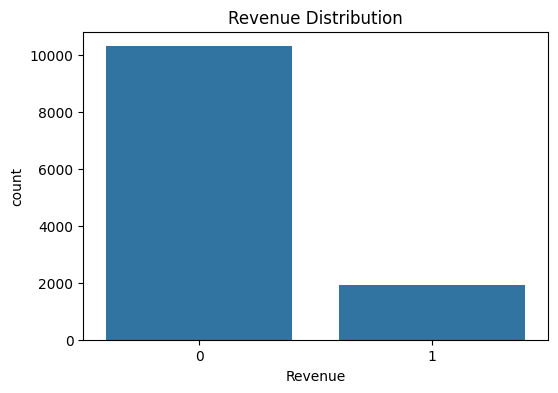

In [120]:
# Revenue Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Revenue', data=df)
plt.title("Revenue Distribution")
plt.show()


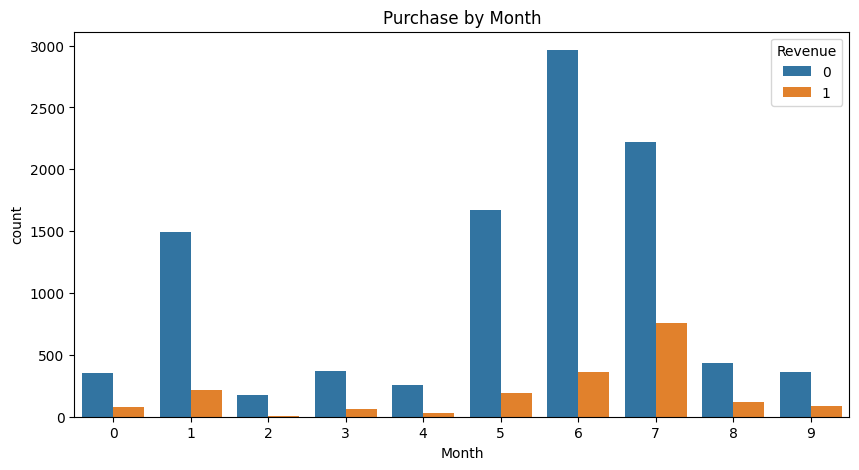

In [121]:
# Purchase by Month
plt.figure(figsize=(10,5))
sns.countplot(x='Month', hue='Revenue', data=df)
plt.title("Purchase by Month")
plt.show()


Most active users are in may and most products sold are in November

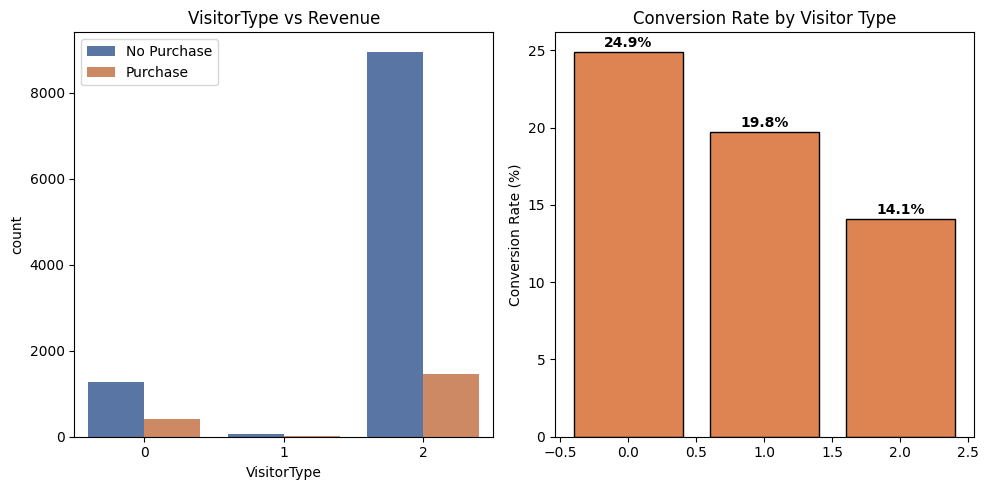

VisitorType
0    24.93
1    19.75
2    14.09
Name: Revenue, dtype: float64


In [122]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Define the missing variables
TARGET = 'Revenue'
FIGURES_DIR = Path('.') # Save in current working directory
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.countplot(data=df, x='VisitorType', hue=TARGET, ax=axes[0],
              palette=['#4C72B0', '#DD8452'])
axes[0].set_title('VisitorType vs Revenue')
axes[0].legend(['No Purchase', 'Purchase'])

vt_conv = df.groupby('VisitorType')[TARGET].mean() * 100
axes[1].bar(vt_conv.index, vt_conv.values, color='#DD8452', edgecolor='black')
axes[1].set_title('Conversion Rate by Visitor Type')
axes[1].set_ylabel('Conversion Rate (%)')
for i, (idx, val) in enumerate(vt_conv.items()):
    axes[1].text(i, val + 0.3, f'{val:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'visitortype_vs_revenue.png', dpi=120)
plt.show()
print(vt_conv.round(2))

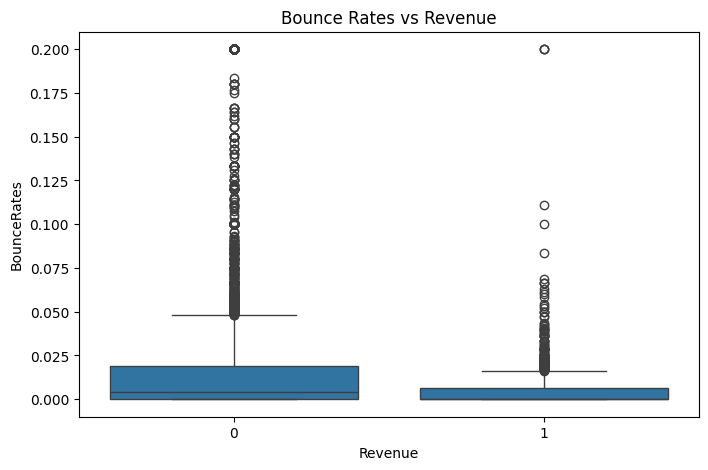

In [123]:
# Bounce Rates
plt.figure(figsize=(8,5))
sns.boxplot(x='Revenue', y='BounceRates', data=df)
plt.title("Bounce Rates vs Revenue")
plt.show()


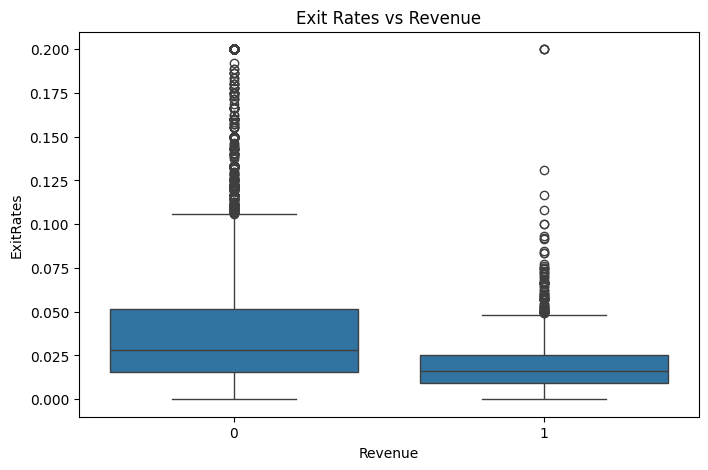

In [124]:
# Exit Rates
plt.figure(figsize=(8,5))
sns.boxplot(x='Revenue', y='ExitRates', data=df)
plt.title("Exit Rates vs Revenue")
plt.show()


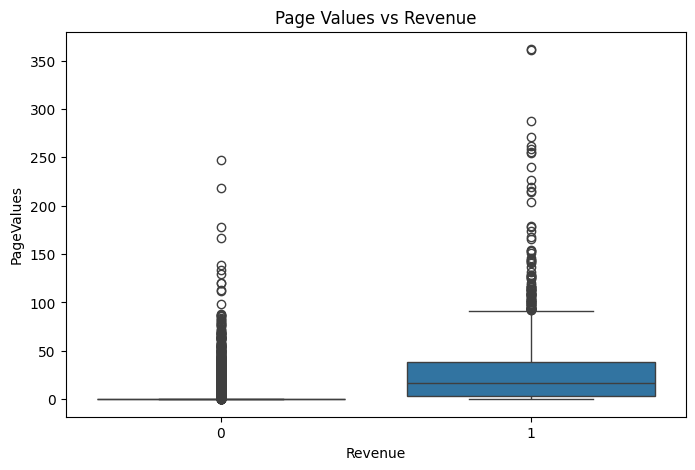

In [125]:
# Page Values
plt.figure(figsize=(8,5))
sns.boxplot(x='Revenue', y='PageValues', data=df)
plt.title("Page Values vs Revenue")
plt.show()

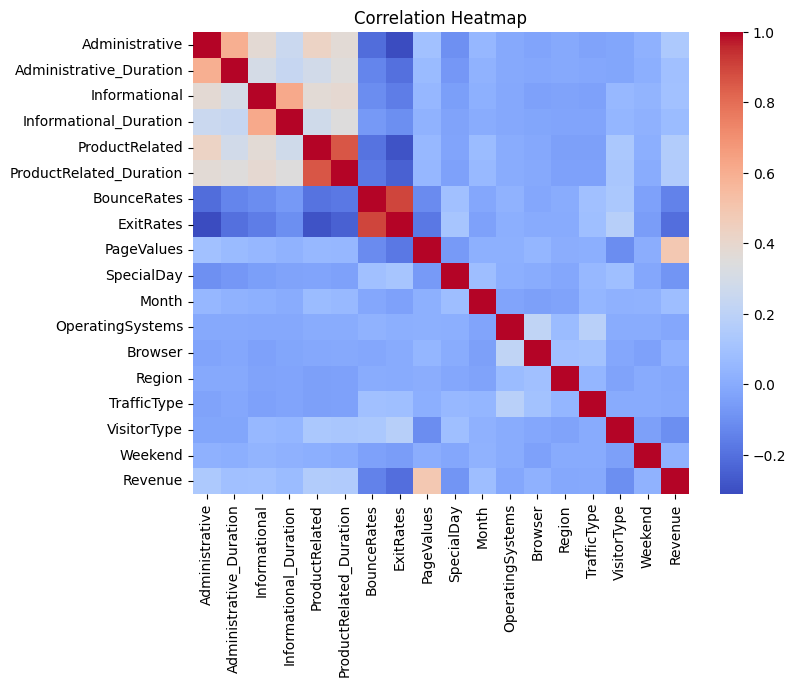

In [126]:
# Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

/tmp/ipykernel_827/2977718794.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Weekday', 'Weekend'])


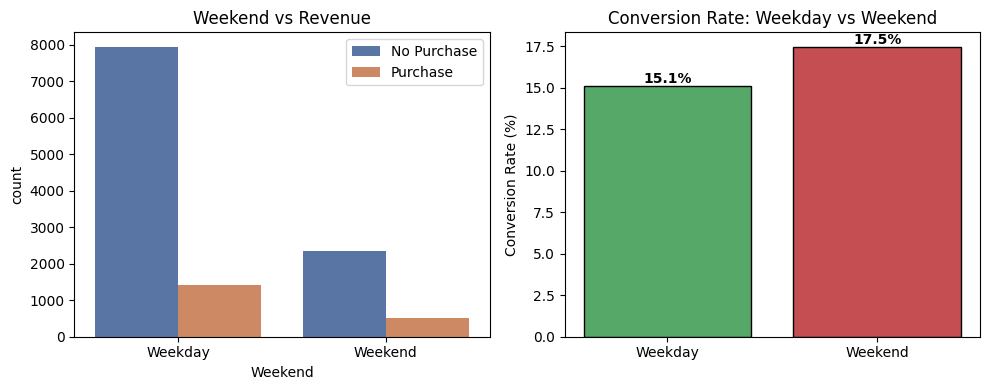

Conversion rate (Weekday/Weekend): {0: 15.08, 1: 17.45}


In [127]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=df, x='Weekend', hue=TARGET, ax=axes[0],
              palette=['#4C72B0', '#DD8452'])
axes[0].set_title('Weekend vs Revenue')
axes[0].set_xticklabels(['Weekday', 'Weekend'])
axes[0].legend(['No Purchase', 'Purchase'])

we_conv = df.groupby('Weekend')[TARGET].mean() * 100
axes[1].bar(['Weekday', 'Weekend'], we_conv.values, color=['#55A868','#C44E52'], edgecolor='black')
axes[1].set_title('Conversion Rate: Weekday vs Weekend')
axes[1].set_ylabel('Conversion Rate (%)')
for i, val in enumerate(we_conv.values):
    axes[1].text(i, val + 0.2, f'{val:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'weekend_vs_revenue.png', dpi=120)
plt.show()
print('Conversion rate (Weekday/Weekend):', we_conv.round(2).to_dict())

In [128]:
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)

In [129]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Month'] = le.fit_transform(df['Month'])
df['VisitorType'] = le.fit_transform(df['VisitorType'])

In [130]:
from sklearn.model_selection import train_test_split
X = df.drop('Revenue', axis=1)
y = df['Revenue']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify= y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(9764, 17)
(2441, 17)
(9764,)
(2441,)


In [131]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {

    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    )

}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    accuracy = accuracy_score(y_test, prediction)
    precision = precision_score(y_test, prediction)
    recall = recall_score(y_test, prediction)
    f1 = f1_score(y_test, prediction)

    # Append results to the list
    results.append([name, accuracy, precision, recall, f1])

# Create the result DataFrame
result_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
)

# Sort by Accuracy
result_df = result_df.sort_values(by="Accuracy", ascending=False)

# Best Model
best_model = result_df.iloc[0]

print(result_df)
print("\n" + "="*50)
print("🏆 BEST MODEL")
print("="*50)
print(f"Model Name : {best_model['Model']}")
print(f"Accuracy   : {best_model['Accuracy']:.4f}")
print(f"Precision  : {best_model['Precision']:.4f}")
print(f"Recall     : {best_model['Recall']:.4f}")
print(f"F1 Score   : {best_model['F1 Score']:.4f}")
print("="*50)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


                 Model  Accuracy  Precision    Recall  F1 Score
2        Random Forest  0.902089   0.731392  0.591623  0.654124
4              XGBoost  0.893077   0.681682  0.594241  0.634965
0  Logistic Regression  0.884883   0.746341  0.400524  0.521295
1        Decision Tree  0.871364   0.587179  0.599476  0.593264
3                  KNN  0.856616   0.580808  0.301047  0.396552

🏆 BEST MODEL
Model Name : Random Forest
Accuracy   : 0.9021
Precision  : 0.7314
Recall     : 0.5916
F1 Score   : 0.6541


In [132]:

# Create SMOTE object
smote = SMOTE(random_state=42)

# Apply SMOTE only on training data
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Check class distribution
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Revenue
0    8238
1    1526
Name: count, dtype: int64

After SMOTE:
Revenue
1    8238
0    8238
Name: count, dtype: int64


In [133]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd

# Dictionary of models
models = {

    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        min_samples_split=5,
        min_samples_leaf=2,
        max_depth=20,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    )

}

results = []

# Train every model using SMOTE data
for name, model in models.items():

    # Train on SMOTE dataset
    model.fit(X_train_smote, y_train_smote)

    # Predict on original test set
    y_pred = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_pred)

    # Store results
    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        roc
    ])

# Create DataFrame
result_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
)

# Sort by F1 Score
result_df = result_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(result_df)

# Best Model
best_model_name = result_df.iloc[0]["Model"]

best_model = models[best_model_name]

print("\n" + "="*50)
print("🏆 BEST MODEL")
print("="*50)
print(f"Model      : {best_model_name}")
print(f"Accuracy   : {result_df.iloc[0]['Accuracy']:.4f}")
print(f"Precision  : {result_df.iloc[0]['Precision']:.4f}")
print(f"Recall     : {result_df.iloc[0]['Recall']:.4f}")
print(f"F1 Score   : {result_df.iloc[0]['F1 Score']:.4f}")
print(f"ROC-AUC    : {result_df.iloc[0]['ROC-AUC']:.4f}")
print("="*50)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
2        Random Forest  0.884883   0.603272  0.772251  0.677382  0.839015
4              XGBoost  0.882016   0.604911  0.709424  0.653012  0.811730
0  Logistic Regression  0.866448   0.555336  0.735602  0.632883  0.813163
1        Decision Tree  0.838591   0.487500  0.612565  0.542923  0.746545
3                  KNN  0.771815   0.366412  0.628272  0.462874  0.713359

🏆 BEST MODEL
Model      : Random Forest
Accuracy   : 0.8849
Precision  : 0.6033
Recall     : 0.7723
F1 Score   : 0.6774
ROC-AUC    : 0.8390


In [134]:
import joblib
import os

# Create a folder for project files
os.makedirs("model_files", exist_ok=True)

# Save the trained classification model
joblib.dump(best_model, "model_files/best_model.pkl")

# Save the fitted scaler
joblib.dump(scaler, "model_files/scaler.pkl")

print("Model, K-Means clustering model, and scaler saved successfully!")

Model, K-Means clustering model, and scaler saved successfully!


In [135]:
from google.colab import files

files.download("model_files/best_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [136]:
files.download("model_files/scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>